# 04 - DATA VISUALISATION REVIEW EXERCISE - TITANIC (SOLUTION)

Import libraries and load Titanic dataset.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
sns.set_style('whitegrid')

In [2]:
titanic = sns.load_dataset('titanic')
titanic.shape

(891, 15)

In [3]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Plot the number of passengers per sex. Which plot is most suitable? Add all default elements for a readable graph.

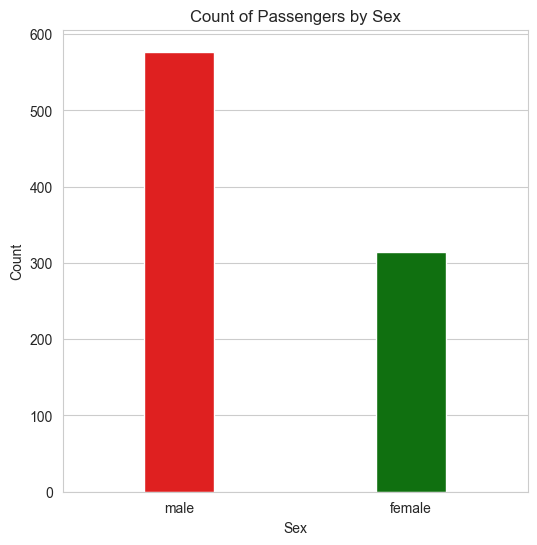

In [3]:
# Set figure size
plt.figure(figsize=(6, 6))  # Adjust the width and height as needed

# Create the countplot
sns.countplot(x='sex', data=titanic, width=0.3, hue='sex', palette={'male': 'red', 'female': 'green'})

# Add labels and title
plt.xlabel('Sex')
plt.ylabel('Count')
plt.title('Count of Passengers by Sex')

# Show plot
plt.show()

Plot a boxplot showing the age distribution for the different classes on the titanic (i.e., one boxplot for each class). Do this with just one boxplot function call. Give each class a different color, don't use a legend. Add title and labels.

What can we learn from these plots?

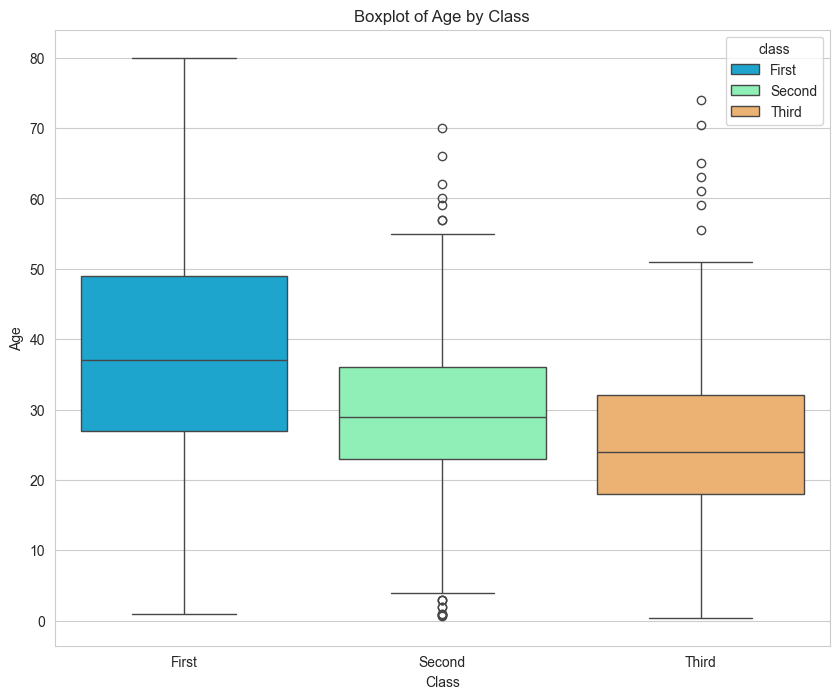

In [4]:
plt.figure(figsize=(10, 8))  # Adjust the width and height as needed

sns.boxplot(x='class', y='age', data=titanic, hue='class', palette='rainbow', legend=True)
# Add labels and title
plt.xlabel('Class')
plt.ylabel('Age')
plt.title('Boxplot of Age by Class')

# Show plot
plt.show()

Do the same but now for the people who survived vs. the ones who didn't. Use the object-oriented way of creating a figure for this exercise (plt.subplots()) (figsize: (5,5))

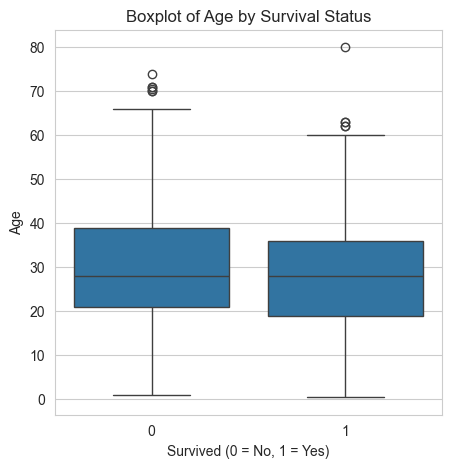

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

## Create the figure and axes object, setting the figure size
f, ax = plt.subplots(figsize=(5, 5))

# Create the boxplot of Age by Survival status
sns.boxplot(x='survived', y='age', data=titanic, ax=ax)
# Draws the plot on a specific Matplotlib axis (ax), useful when plotting in subplots

# Add labels and a title for clarity
ax.set_title('Boxplot of Age by Survival Status')
ax.set_xlabel('Survived (0 = No, 1 = Yes)')
ax.set_ylabel('Age')

# Show the plot
plt.show()

Create a boxplot that shows the distributions of age for male and female passengers. In addition, for each sex, show a separate boxplot for the ones who survived and the ones who didn't (hint: use hue for this))

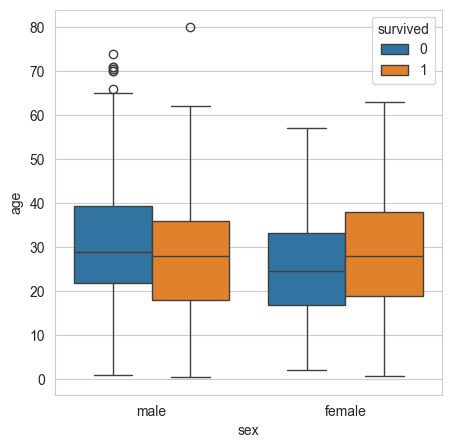

In [6]:
f, ax = plt.subplots(figsize=(5,5))
sns.boxplot(x="sex", y="age", hue="survived", data=titanic, ax=ax);

Plot a barplot that shows the survival rate of passengers from each class and within each class for each sex.
What does the bar plot reveal about the survival rates of different passenger classes on the Titanic, and how do these rates vary between male and female passengers?

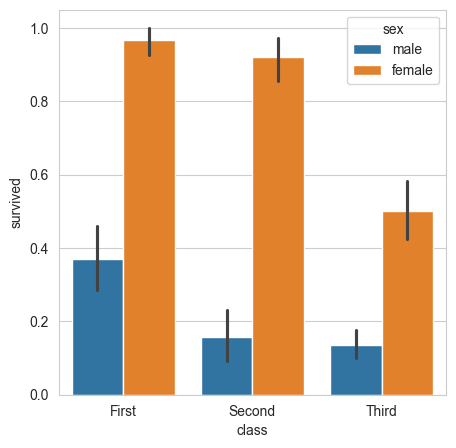

In [7]:
f, ax = plt.subplots(figsize=(5,5))
sns.barplot(x="class", y="survived",hue="sex", data=titanic, ax=ax);

Create a count plot (using catplot) that shows the number of passengers on the Titanic by demographic categories (men, women, and children)

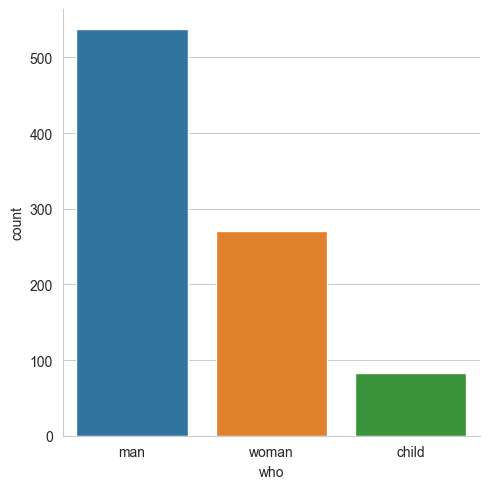

In [8]:
# Catplot is a figure-level function and does not accept target axes
sns.catplot(x='who', data=titanic, hue='who', kind='count')

What does the distribution of ages for the survivors of the Titanic reveal about the age demographics of those who survived the disaster? Choose an appropriate plot

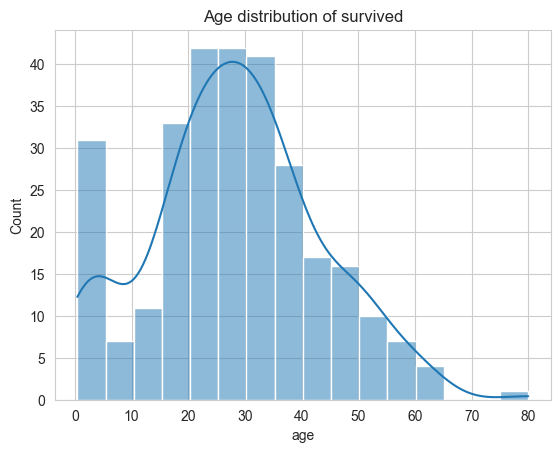

In [9]:
survived_age = titanic.loc[titanic['survived']==1,"age"].dropna()
sns.histplot(survived_age, kde=True)
plt.title("Age distribution of survived");
# Correct labels are added automatically

What does the distribution of ages for passengers who did not survive the Titanic reveal about the age demographics of those who perished in the disaster?

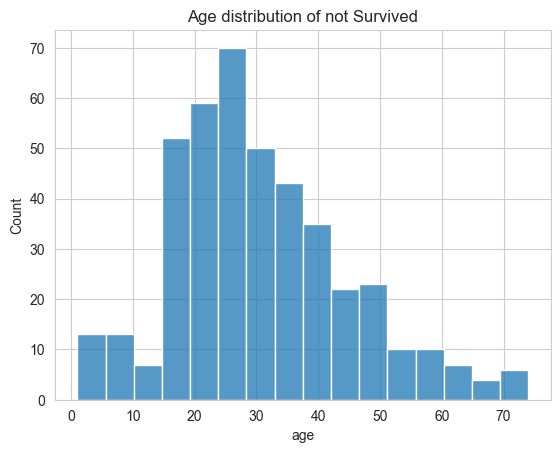

In [10]:
not_survived_age = titanic.loc[titanic['survived']==0,"age"].dropna()
sns.histplot(not_survived_age)
plt.title("Age distribution of not Survived");

How does the kernel density estimate (KDE) plot of age distribution for male and female passengers on the Titanic illustrate differences in survival based on gender? Use a FacetGrid to plot your solution.

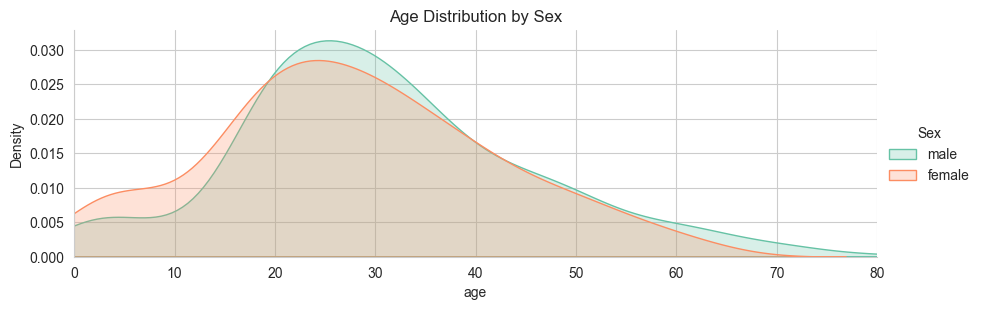

In [11]:
# Define a color palette
palette = sns.color_palette('Set2')  # or any other palette you prefer

# Create the FacetGrid
fg = sns.FacetGrid(titanic, hue="sex", aspect=3, palette=palette)

# Map the KDE plot
fg.map(sns.kdeplot, "age", fill=True)

# Set x limits for the plot
fg.set(xlim=(0, 80))

# Add a title and legend
fg.add_legend(title='Sex')
plt.title('Age Distribution by Sex')

# Show the plot
plt.show()

What does a violin plot show about the distribution of ticket fares across different passenger classes on the Titanic?

Text(0, 0.5, 'Fare')

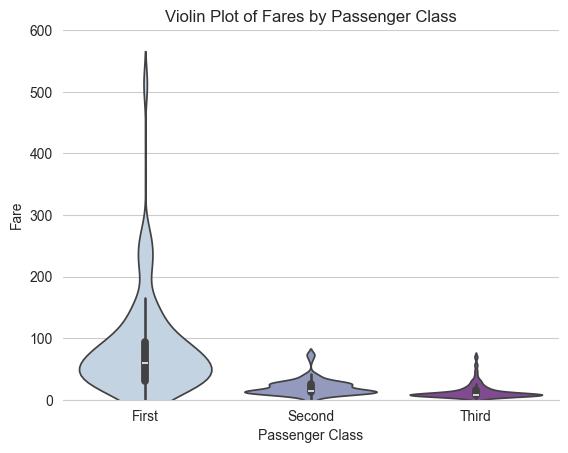

In [12]:
# Create the violin plot
sns.violinplot(x='class', y='fare', data=titanic, hue='class', palette='BuPu')

# Set the y-axis limits
plt.ylim(0, 600)

# Remove the left spine for aesthetics
sns.despine(left=True)

plt.title('Violin Plot of Fares by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Fare')

What does the regression plot of fare against age reveal about the relationship between these two variables among Titanic passengers?

Text(0, 0.5, 'Fare')

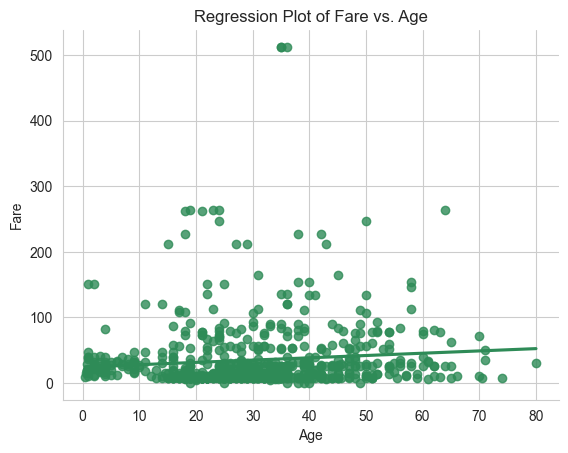

In [13]:
# Create the regression plot without robust=True
sns.regplot(x="age", y="fare", data=titanic, ci=None, color="seagreen")
# Look up what ci does

# Remove the top and right spines for aesthetics
sns.despine()
plt.title('Regression Plot of Fare vs. Age')
plt.xlabel('Age')
plt.ylabel('Fare')

What insights can be drawn from a pair plot of the Titanic dataset regarding the relationships between multiple numerical features?

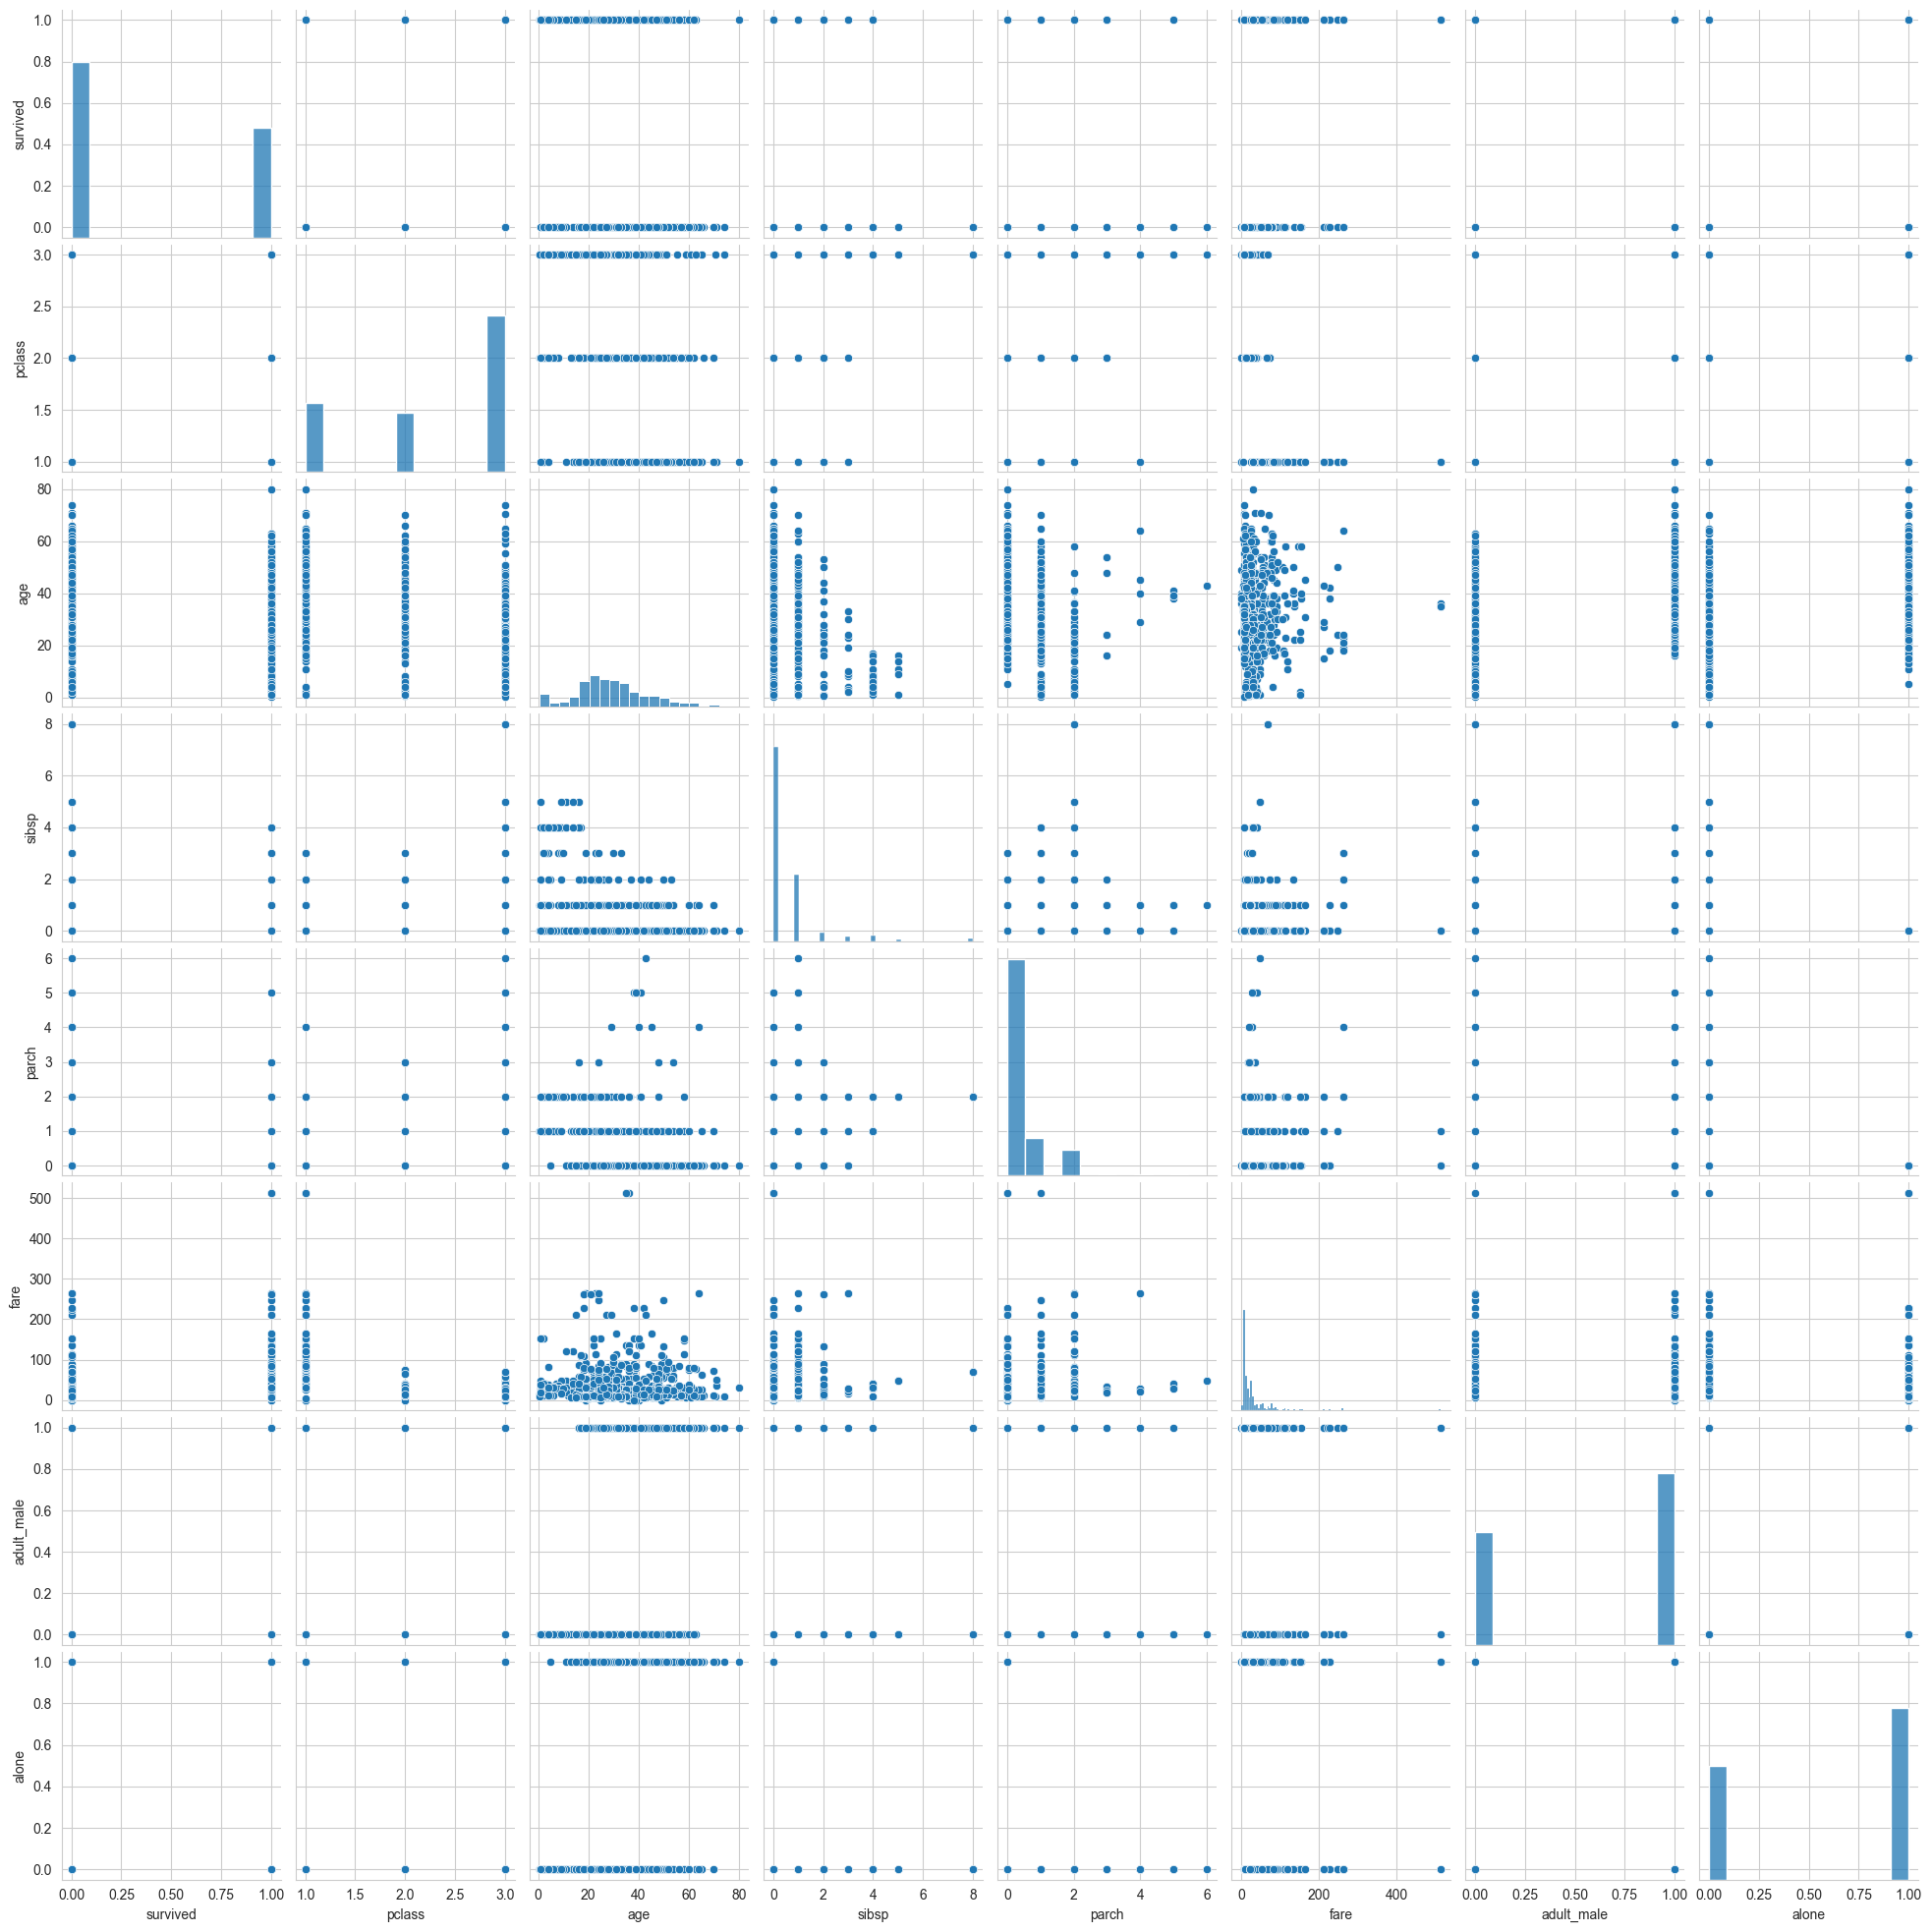

In [14]:
sns.pairplot(titanic);

Create the same pair plot as the previous exercise but now with color coding based on the pclass variable (passenger class)

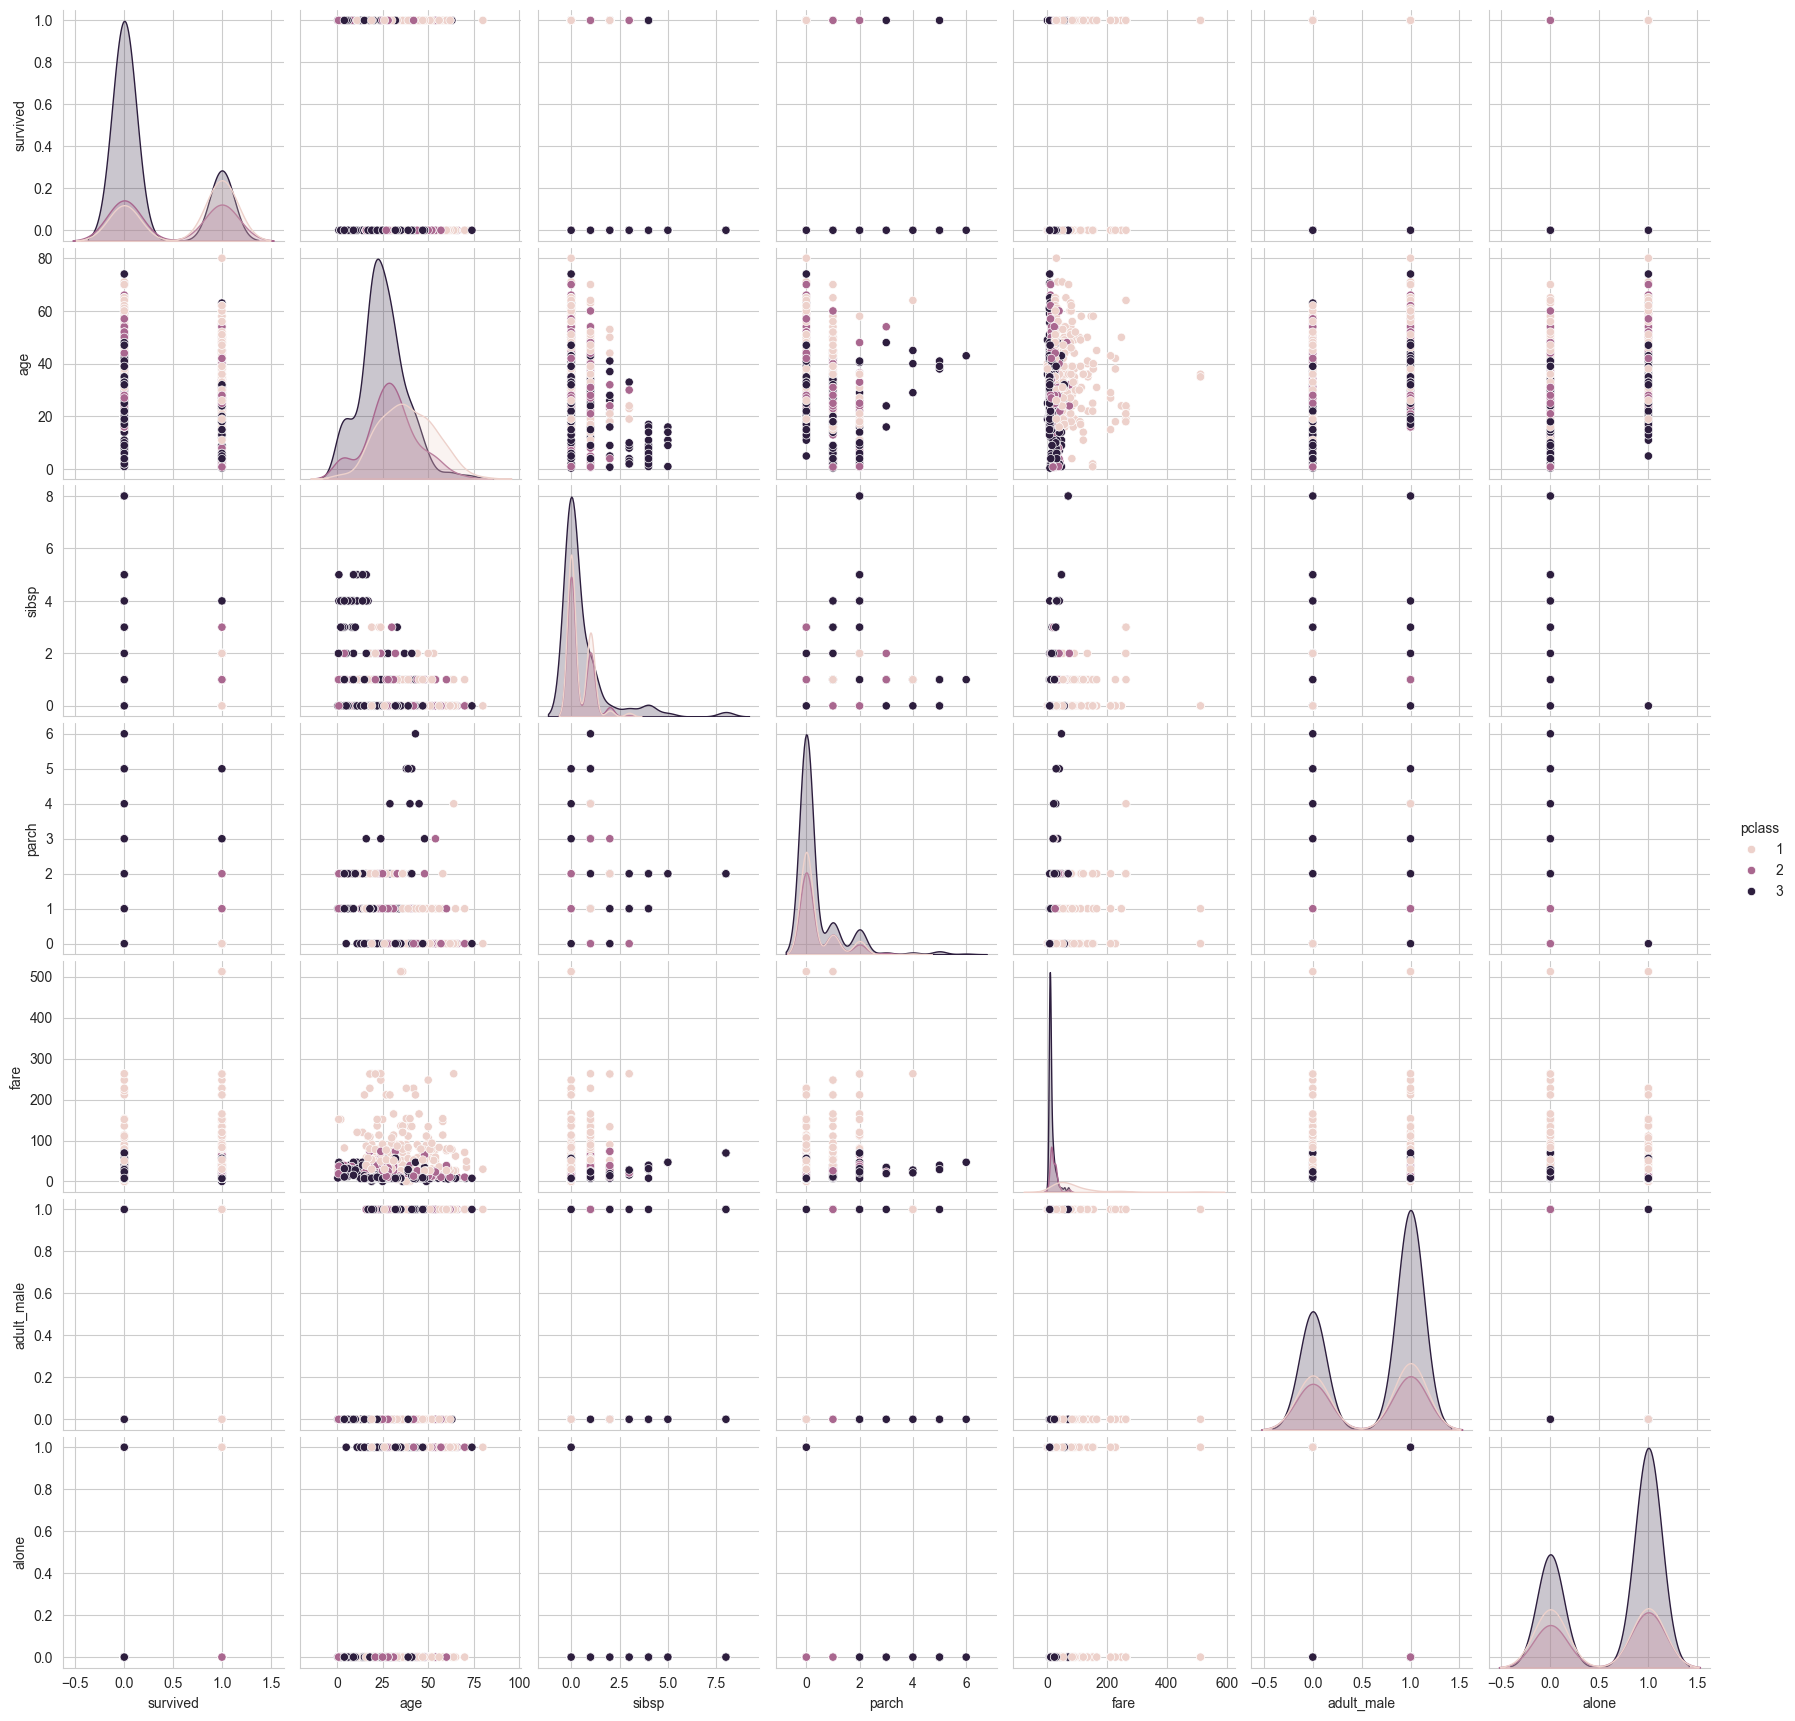

In [15]:
sns.pairplot(titanic, hue="pclass")

Create an informative scatter plot with a customized colorbar to represent categorical data in the Titanic dataset.
- For example you can show scatter plot of age versus fare colored by passenger class.
- Or be creative!

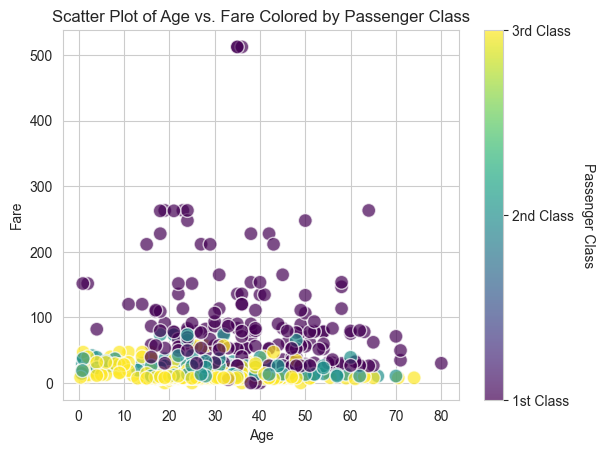

In [16]:
# Use a colormap to map pclass to colors
scatter = plt.scatter(
    data=titanic, 
    x='age', 
    y='fare', 
    c='pclass',          # Use passenger class for coloring
    cmap='viridis',      # Custom colormap
    alpha=0.7,          # Set transparency
    edgecolor='w',      # White edge color for better visibility
    s=100                # Size of the points
)

# Customize the colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('Passenger Class', rotation=270, labelpad=15)  # Label for the colorbar
cbar.set_ticks([1, 2, 3])  # Specify the ticks
cbar.ax.set_yticklabels(['1st Class', '2nd Class', '3rd Class'])  # Custom labels for ticks

# Set the title and labels
plt.title('Scatter Plot of Age vs. Fare Colored by Passenger Class')
plt.xlabel('Age')
plt.ylabel('Fare')

# Show the plot
plt.show()